# 01 - Data Audit and Exploratory Data Analysis

**Project:** Used-car price prediction (Devixo Solutions AI/ML Internship, Task 03)
**Dataset:** `data/raw/car_details_v3.csv` (Kaggle "Vehicle dataset from CarDekho" family, file *Car details v3*)
**Goal of this notebook:** understand the data *before* changing anything. This notebook is **read-only**: it audits the raw file, finds quality problems, and records the decisions that the next notebooks will implement.

**What we want to learn**
1. How big is the data, and does it meet the 3,000-row minimum from the task sheet?
2. Which columns have missing, invalid or badly formatted values?
3. Are there duplicate rows?
4. What does the target (`selling_price`) look like?
5. Which features visibly relate to price?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")          # keep notebook output readable

# Work out the project root so the notebook runs from anywhere inside the repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.car_features import CarFeatureEngineer, RAW_INPUT_COLUMNS

DATA_PATH = ROOT / "data" / "raw" / "car_details_v3.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.2 | numpy 2.4.4


## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
display(df.head())
df.info()

Shape (rows, columns): (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


## 2. Data-quality audit

Three kinds of problems to look for: (a) real missing values, (b) "hidden" invalid values that are not empty but are not real measurements either, and (c) duplicate rows.

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(quality)
print("Rows with at least one missing value:", int(df.isna().any(axis=1).sum()))

,dtype,missing,missing_%,unique_values
name,str,0,0.00,2058
year,int64,0,0.00,29
selling_price,int64,0,0.00,677
km_driven,int64,0,0.00,921
fuel,str,0,0.00,4
seller_type,str,0,0.00,3
transmission,str,0,0.00,2
owner,str,0,0.00,5
mileage,str,221,2.72,393
engine,str,221,2.72,121


Rows with at least one missing value: 222


In [4]:
# (b) Hidden invalid values: present in the file, but not usable as numbers
leading_number = r"^\s*(\d+(?:\.\d+)?)"
mileage_num = df["mileage"].str.extract(leading_number)[0].astype(float)

hidden = {
    "mileage is exactly 0": int((mileage_num == 0).sum()),
    "max_power has no number (just ' bhp')": int((df["max_power"].notna() & ~df["max_power"].fillna("").str.contains(r"\d")).sum()),
    "km_driven <= 1,000": int((df["km_driven"] <= 1000).sum()),
}
print(pd.Series(hidden, name="rows").to_string())

# (c) Duplicates
n_dup = int(df.duplicated().sum())
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"\nExact duplicate rows: {n_dup} ({n_dup / len(df):.1%} of the file)")
print(f"Rows after removing duplicates: {len(df_clean)}")

# Task-sheet requirement: dataset must have at least 3,000 rows
assert len(df_clean) >= 3000, "Dataset is below the 3,000-row requirement"
print("3,000-row requirement satisfied after de-duplication: OK")

mileage is exactly 0                     17
max_power has no number (just ' bhp')     1
km_driven <= 1,000                        7

Exact duplicate rows: 1202 (14.8% of the file)
Rows after removing duplicates: 6926
3,000-row requirement satisfied after de-duplication: OK


**Why remove exact duplicates?** The file has no listing ID, so two identical rows *could* be two different cars. But two rows that match on all 13 columns, including the exact price and exact kilometres, are far more likely to be the same listing scraped twice. The task sheet also lists "Remove duplicates" as a required step. We will state this as an **assumption** in the README. De-duplicating also matters for honesty of evaluation: if copies of a row landed in both train and test, the test score would be inflated.

In [5]:
# Missing values AFTER duplicates are removed (these are the ones we must handle)
missing_after = df_clean.isna().sum()
display(missing_after[missing_after > 0].to_frame("missing").assign(**{"%": (missing_after[missing_after > 0] / len(df_clean) * 100).round(2)}))

cols = ["mileage", "engine", "max_power", "seats", "torque"]
print("Rows where ALL of", cols, "are missing together:", int(df_clean[cols].isna().all(axis=1).sum()))
print("Rows with ANY of them missing:", int(df_clean[cols].isna().any(axis=1).sum()))

,missing,%
mileage,208,3.00
engine,208,3.00
max_power,205,2.96
torque,209,3.02
seats,208,3.00


Rows where ALL of ['mileage', 'engine', 'max_power', 'seats', 'torque'] are missing together: 205
Rows with ANY of them missing: 209


## 3. Text columns that should be numbers

`mileage`, `engine` and `max_power` are stored as text with units. A model cannot use "23.4 kmpl" directly, so we need to look at the unit patterns before we parse them.

In [6]:
unit_pattern = r"([A-Za-z/]+)\s*$"
for col in ["mileage", "engine", "max_power"]:
    units = df_clean[col].str.extract(unit_pattern)[0].value_counts(dropna=False)
    print(f"--- unit found at end of '{col}' ---")
    print(units.to_string(), "\n")

print("--- mileage unit by fuel type (is km/kg only used for gas fuels?) ---")
unit_by_fuel = pd.crosstab(df_clean["fuel"], df_clean["mileage"].str.extract(unit_pattern)[0].fillna("missing"))
display(unit_by_fuel)

print("--- `torque` sample (free text, mixed formats) ---")
print(df_clean["torque"].dropna().sample(8, random_state=1).to_string())

--- unit found at end of 'mileage' ---
0
kmpl     6631
NaN       208
km/kg      87 



--- unit found at end of 'engine' ---
0
CC     6718
NaN     208 

--- unit found at end of 'max_power' ---
0
bhp    6718
NaN     208 

--- mileage unit by fuel type (is km/kg only used for gas fuels?) ---


,km/kg,kmpl,missing
fuel,,,
CNG,52,0,4
Diesel,0,3658,97
LPG,35,0,3
Petrol,0,2973,104


--- `torque` sample (free text, mixed formats) ---
793       113.75nm@ 4000rpm
4441          62Nm@ 3000rpm
771           90Nm@ 3500rpm
3844    350Nm@ 1750-2500rpm
3297    240Nm@ 1600-2800rpm
4793          90Nm@ 3500rpm
6443         248Nm@ 2250rpm
6807         190Nm@ 2000rpm


## 4. Numeric and categorical overview

In [7]:
display(df_clean[["year", "selling_price", "km_driven"]].describe().round(0))
for col in ["fuel", "seller_type", "transmission", "owner", "seats"]:
    print(f"--- {col} ---")
    print(df_clean[col].value_counts(dropna=False).to_string(), "\n")
print("Distinct car names:", df_clean["name"].nunique())

,year,selling_price,km_driven
count,6926.0,6926.0,6926.0
mean,2013.0,517271.0,73996.0
std,4.0,519767.0,58358.0
min,1983.0,29999.0,1.0
25%,2011.0,250000.0,40000.0
50%,2014.0,400000.0,70000.0
75%,2017.0,633500.0,100000.0
max,2020.0,10000000.0,2360457.0


--- fuel ---
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38 

--- seller_type ---
seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27 

--- transmission ---
transmission
Manual       6342
Automatic     584 

--- owner ---
owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5 

--- seats ---
seats
5.0     5254
7.0      966
8.0      222
NaN      208
4.0      124
9.0       74
6.0       57
10.0      18
2.0        2
14.0       1 

Distinct car names: 2058


## 5. The target: `selling_price`

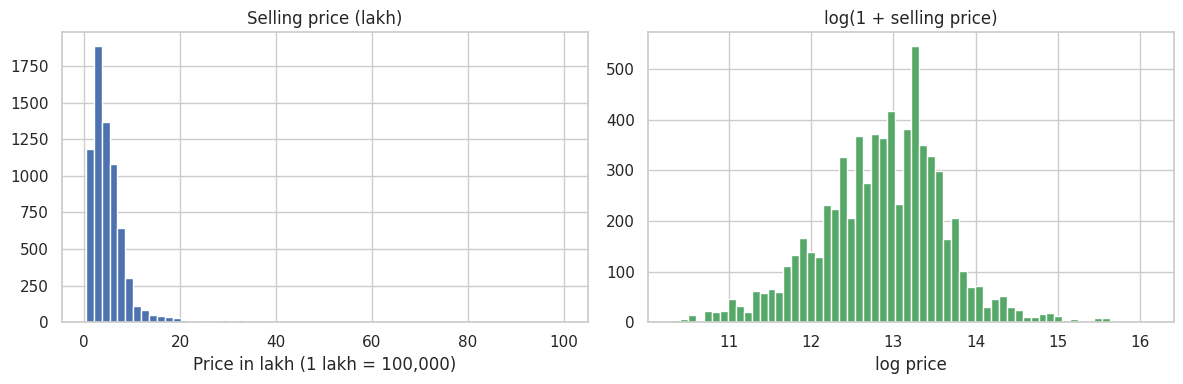

Skewness of price:      5.57
Skewness of log(price): -0.16
Min / median / max price: 29,999 / 400,000 / 10,000,000


In [8]:
price = df_clean["selling_price"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(price / 1e5, bins=60, color="#4C72B0")
axes[0].set_title("Selling price (lakh)")
axes[0].set_xlabel("Price in lakh (1 lakh = 100,000)")
axes[1].hist(np.log1p(price), bins=60, color="#55A868")
axes[1].set_title("log(1 + selling price)")
axes[1].set_xlabel("log price")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_target_distribution.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Skewness of price:      {price.skew():.2f}")
print(f"Skewness of log(price): {np.log1p(price).skew():.2f}")
print(f"Min / median / max price: {price.min():,.0f} / {price.median():,.0f} / {price.max():,.0f}")

## 6. Unusual values: inspect before deciding

We list suspicious rows but **do not delete anything here**. Extreme does not mean wrong (a luxury car really can cost 10 million).

In [9]:
show = ["name", "year", "selling_price", "km_driven", "fuel", "owner"]
print("Highest km_driven:");  display(df_clean.nlargest(6, "km_driven")[show])
print("Lowest km_driven:");   display(df_clean.nsmallest(6, "km_driven")[show])
print("Highest prices:");     display(df_clean.nlargest(5, "selling_price")[show])
print("Lowest prices:");      display(df_clean.nsmallest(5, "selling_price")[show])
print("Rows with mileage == 0:")
display(df_clean[df_clean["mileage"].str.extract(leading_number)[0].astype(float) == 0][show + ["mileage"]].head(8))
print("Count of 0-mileage rows:", int((df_clean["mileage"].str.extract(leading_number)[0].astype(float) == 0).sum()))

Highest km_driven:


,name,year,selling_price,km_driven,fuel,owner
3161,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol,Second Owner
1646,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel,First Owner
3183,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol,Second Owner
3284,Maruti Wagon R VXI BS IV,2011,229999,500000,Petrol,Second Owner
5744,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel,Second Owner
4411,Mahindra Scorpio M2DI,2011,400000,475000,Diesel,Third Owner


Lowest km_driven:


,name,year,selling_price,km_driven,fuel,owner
6737,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,209000,1,CNG,Fourth & Above Owner
393,Honda City i-VTEC CVT V,2018,1085000,1000,Petrol,First Owner
2714,Maruti Swift AMT VXI,2020,654000,1000,Petrol,First Owner
5710,Toyota Innova Crysta 2.4 ZX AT,2020,2300000,1000,Diesel,First Owner
6409,Maruti Swift LXI,2020,445000,1000,Petrol,First Owner
6450,Hyundai Santro Magna,2020,500000,1000,Petrol,First Owner


Highest prices:


...

Lowest prices:


,name,year,selling_price,km_driven,fuel,owner
4943,Maruti 800 AC,1997,29999,80000,Petrol,Third Owner
1953,Maruti Zen LXI,2001,30000,10000,Petrol,First Owner
5825,Hyundai Santro GLS I - Euro I,2000,30000,90000,Petrol,Third Owner
5170,Maruti 800 Std,2000,31000,56194,Petrol,Fourth & Above Owner
1742,Maruti 800 Std,2004,31504,110000,Petrol,Third Owner


Rows with mileage == 0:


,name,year,selling_price,km_driven,fuel,owner,mileage
614,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Second Owner,0.0 kmpl
736,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Second Owner,0.0 kmpl
1504,Hyundai Santro Xing GL,2008,105000,128000,Petrol,First Owner,0.0 kmpl
1531,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Third Owner,0.0 kmpl
1945,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,First Owner,0.0 kmpl
2169,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Second Owner,0.0 kmpl
2488,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,First Owner,0.0 kmpl
4558,Hyundai Santro Xing GL,2008,175000,40000,Petrol,First Owner,0.0 kmpl


Count of 0-mileage rows: 15


## 7. Relationships with price

Charts below use a **log scale** on price because price spans from about 30 thousand to 10 million.

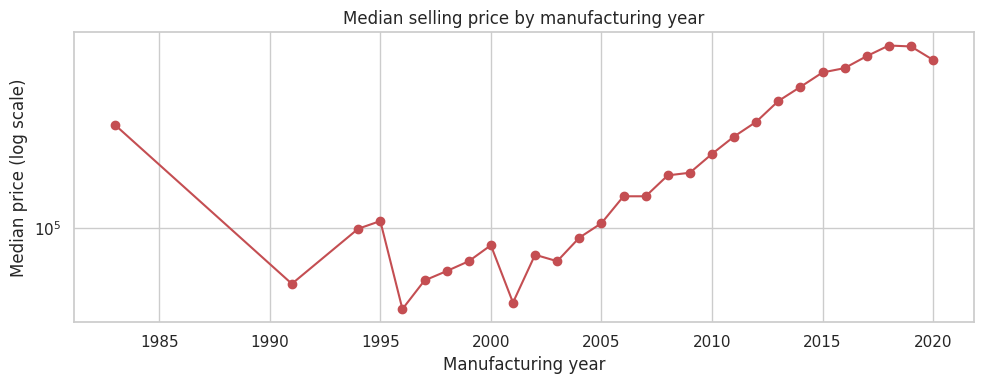

Listings per year (last 8 years in data):
year
2013    562
2014    581
2015    681
2016    693
2017    808
2018    608
2019    347
2020     63
Years with fewer than 10 listings: 6 of 29


In [10]:
by_year = df_clean.groupby("year")["selling_price"].agg(["median", "count"])
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(by_year.index, by_year["median"], marker="o", color="#C44E52")
ax1.set_yscale("log")
ax1.set_ylabel("Median price (log scale)")
ax1.set_xlabel("Manufacturing year")
ax1.set_title("Median selling price by manufacturing year")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_price_by_year.png", dpi=130, bbox_inches="tight")
plt.show()
print("Listings per year (last 8 years in data):")
print(by_year["count"].tail(8).to_string())
print("Years with fewer than 10 listings:", int((by_year["count"] < 10).sum()), "of", len(by_year))

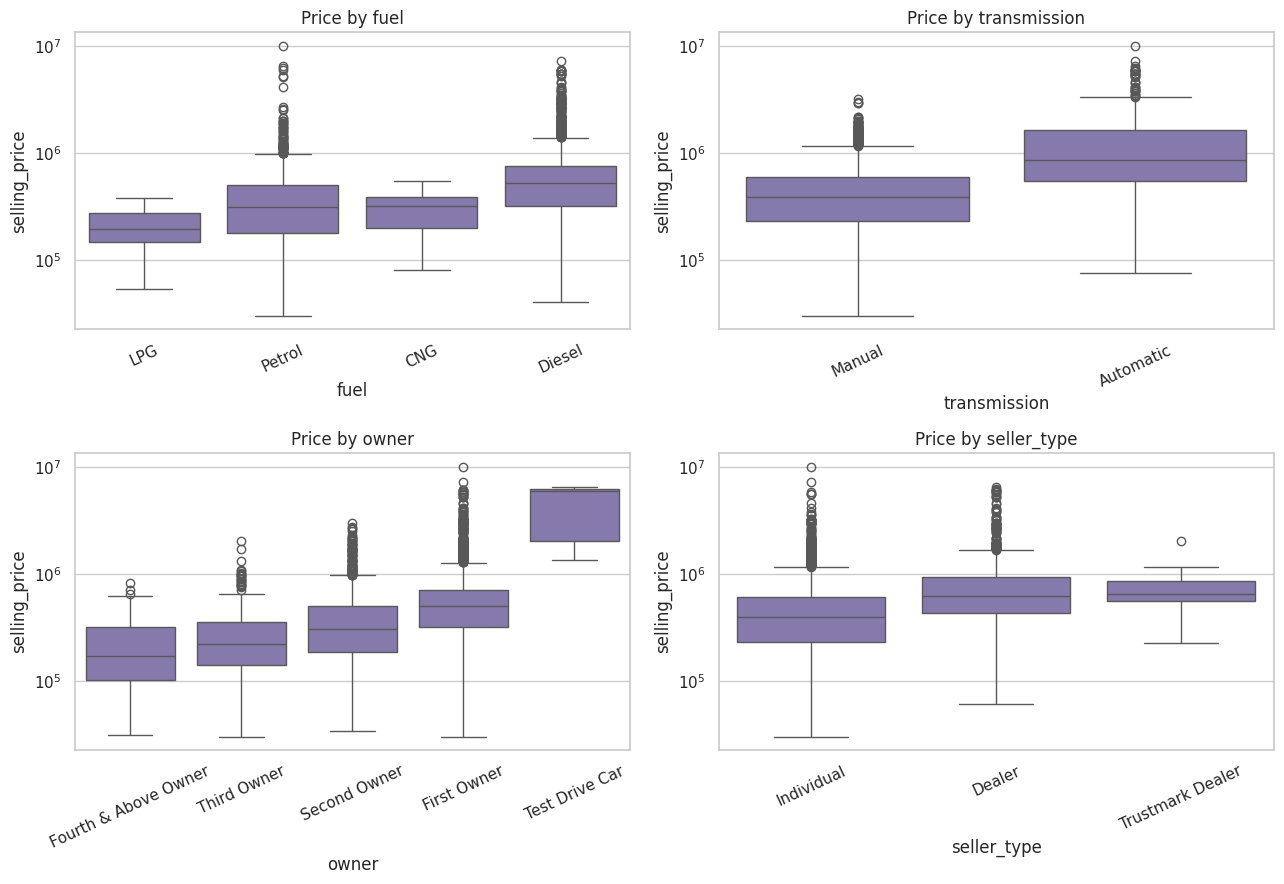

Median price by fuel:
          median  count
fuel                   
LPG     195500.0     38
Petrol  310000.0   3077
CNG     320000.0     56
Diesel  520000.0   3755 

Median price by transmission:
                median  count
transmission                 
Manual        385000.0   6342
Automatic     850000.0    584 

Median price by owner:
                         median  count
owner                                 
Fourth & Above Owner   170000.0    169
Third Owner            222500.0    536
Second Owner           305000.0   1974
First Owner            500000.0   4242
Test Drive Car        5923000.0      5 

Median price by seller_type:
                    median  count
seller_type                      
Individual        390000.0   6218
Dealer            620000.0    681
Trustmark Dealer  650000.0     27 



In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["fuel", "transmission", "owner", "seller_type"]):
    order = df_clean.groupby(col)["selling_price"].median().sort_values().index
    sns.boxplot(data=df_clean, x=col, y="selling_price", order=order, ax=ax, color="#8172B3")
    ax.set_yscale("log")
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_price_by_category.png", dpi=130, bbox_inches="tight")
plt.show()

for col in ["fuel", "transmission", "owner", "seller_type"]:
    print(f"Median price by {col}:")
    print(df_clean.groupby(col)["selling_price"].agg(["median", "count"]).sort_values("median").round(0).to_string(), "\n")

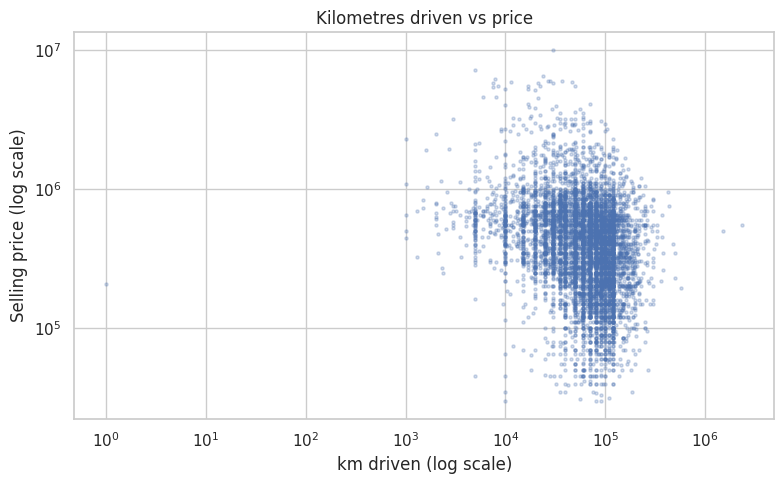

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_clean["km_driven"], df_clean["selling_price"], s=5, alpha=0.25, color="#4C72B0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("km driven (log scale)"); ax.set_ylabel("Selling price (log scale)")
ax.set_title("Kilometres driven vs price")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_price_vs_km.png", dpi=130, bbox_inches="tight")
plt.show()

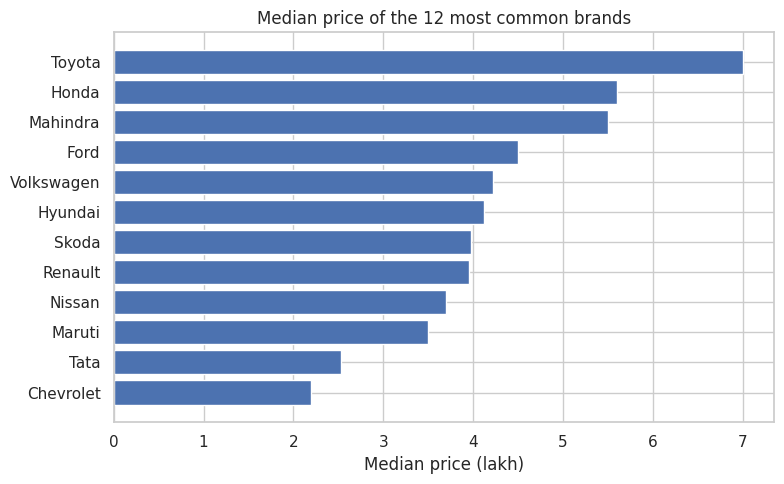

,median,count
brand,,
Chevrolet,220000.0,216
Tata,252999.0,647
Maruti,350000.0,2165
Nissan,370000.0,73
Renault,395000.0,206
Skoda,397500.0,70
Hyundai,412000.0,1267
Volkswagen,422500.0,174
Ford,450000.0,361


Number of distinct brands: 32


In [13]:
df_clean = df_clean.copy()
df_clean["brand"] = df_clean["name"].str.split().str[0].replace({"Land": "Land Rover"})
top = df_clean["brand"].value_counts().head(12).index
brand_stats = (df_clean[df_clean["brand"].isin(top)].groupby("brand")["selling_price"]
               .agg(["median", "count"]).sort_values("median"))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(brand_stats.index, brand_stats["median"] / 1e5, color="#4C72B0")
ax.set_xlabel("Median price (lakh)")
ax.set_title("Median price of the 12 most common brands")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_price_by_brand.png", dpi=130, bbox_inches="tight")
plt.show()
display(brand_stats.round(0))
print("Number of distinct brands:", df_clean["brand"].nunique())

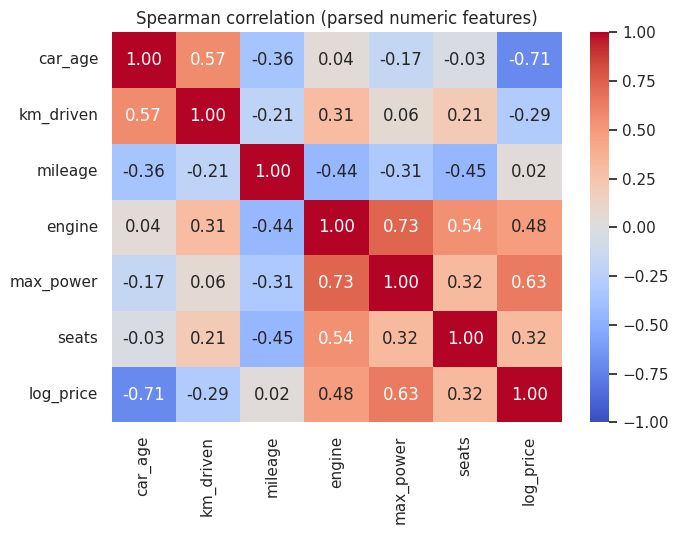

car_age     -0.71
km_driven   -0.29
mileage      0.02
seats        0.32
engine       0.48
max_power    0.63


In [14]:
# Correlation between parsed numeric features and (log) price.
# Spearman = rank correlation, suitable because price is heavily skewed.
parsed = CarFeatureEngineer().fit_transform(df_clean[RAW_INPUT_COLUMNS])
corr_cols = ["car_age", "km_driven", "mileage", "engine", "max_power", "seats"]
corr_df = parsed[corr_cols].copy()
corr_df["log_price"] = np.log1p(df_clean["selling_price"])
corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (parsed numeric features)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_correlation.png", dpi=130, bbox_inches="tight")
plt.show()
print(corr["log_price"].drop("log_price").sort_values().round(2).to_string())

## 8. Findings and decisions

**Facts measured in this notebook (from the actual data)**

| Topic | Finding |
|---|---|
| Size | 8,128 rows x 13 columns in the raw file |
| Duplicates | 1,202 exact duplicate rows (14.8%). **6,926 rows remain**, above the 3,000 minimum |
| Missing values (after de-duplication) | `mileage` 208, `engine` 208, `max_power` 205, `seats` 208, `torque` 209 (about 3.0% each). They are missing **together**: 205 rows have all five missing, 209 rows have at least one |
| Hidden invalid values | 15 rows with `mileage = 0` (not a real measurement), 1 row in the raw file where `max_power` is just " bhp" |
| Units | `mileage` is "kmpl" for 6,631 rows and "km/kg" for 87 rows. **km/kg appears only for CNG (52) and LPG (35) cars**, so the fuel column already tells us which unit applies |
| Target | Price runs from 29,999 to 10,000,000 (median 400,000). Skewness is 5.57 on the raw scale and -0.16 after a log transform |
| Strongest simple relationships (Spearman with log price) | `car_age` -0.71, `max_power` 0.63, `engine` 0.48, `seats` 0.32, `km_driven` -0.29, `mileage` 0.02 |
| Category medians | Automatic 850,000 vs manual 385,000; diesel 520,000 vs petrol 310,000; first owner 500,000 vs fourth-and-above 170,000 |
| Suspicious km values | 2,360,457 km for a 2007 Hyundai i20 and 1,500,000 km for a 2012 Mahindra XUV500 look like typing errors. The highest price (a 10,000,000 Volvo XC90 T8) is plausible for a luxury car |
| Sparse areas | Only 5 "Test Drive Car" owners, 38 LPG and 56 CNG cars; 6 of 29 manufacturing years have fewer than 10 listings; only 63 cars are from 2020 |

**Decisions for the next notebook** (each is a choice we must be able to defend)

1. **Remove exact duplicates before splitting** into train and test, so no listing can appear on both sides. *Assumption:* identical rows are repeated listings, not different cars.
2. **Parse the text columns into numbers** (`mileage`, `engine`, `max_power`). Zero mileage and the blank " bhp" become *missing*, not real values.
3. **Impute the ~3% missing values with the median, inside the pipeline**, using training data only. Because the five columns are missing together, we cannot rebuild one from another, and dropping 3% of rows is a worse trade than imputing.
4. **Keep the km/kg numbers as they are** and let the `fuel` feature explain the unit. *Limitation:* kmpl and km/kg are not strictly comparable, but they never mix within a fuel type.
5. **Do not use `torque`.** It is free text with mixed units (Nm, kgm, rpm ranges), and it is missing in the same rows as power and engine. Parsing it reliably is possible but is future work.
6. **Create `brand` from `name`** (2,058 distinct names is too many to use directly; there are 32 brands). "Land" must be fixed to "Land Rover".
7. **Model log(price)** instead of price, because of the strong skew. We will check this choice with an experiment rather than assume it.
8. **Do not delete the extreme km values by hand.** There are only two, a log transform of `km_driven` will limit their influence, and deleting rows without proof is not justified. We revisit this if the error analysis points at them.
9. **Group very rare categories** (fewer than 10 rows) into one "infrequent" bucket in the encoder.

**Honest limits of this EDA**
- The correlations are associations, not proof that a feature *causes* a higher price (for example, power and engine size move together).
- The price-by-year chart connects sparse early years (before 1998) with straight lines. Treat those points as unreliable.